ANIMAL FACES CLASSIFICATION
=============================================================
Proyek Klasifikasi Gambar untuk Dicoding Submission

Dataset: Animal Faces (andrewmvd/animal-faces)
- Total Images: 16,130 high-quality images
- Resolution: 512x512px
- Classes: 3 classes (cat, dog, wild)
- Target Accuracy: >95%

#####Author: Desnia Anindy Irni Hareva
#####Email: desnia.anindy28@student.uns.ac.id
#####ID Dicoding: desniaanindy

#Persiapan Lingkungan
Bagian ini akan menginstal library yang dibutuhkan dan menyiapkan Kaggle API.

In [1]:
# 0.1: Instalasi Library
print("Langkah 0.1: Menginstal library tambahan...")
!pip install tensorflowjs --quiet
!pip install kagglehub --quiet
print("   - ✅ Library tensorflowjs dan kagglehub siap digunakan.")

# 0.2: Autentikasi Kaggle
# Unggah file 'kaggle.json'
print("\nLangkah 0.2: Menyiapkan Kaggle API...")
from google.colab import files
uploaded = files.upload()

if 'kaggle.json' in uploaded:
    !mkdir -p ~/.kaggle
    !cp kaggle.json ~/.kaggle/
    !chmod 600 ~/.kaggle/kaggle.json
    print("   - ✅ Kaggle API token berhasil disiapkan.")
else:
    print("   - ⚠️ Peringatan: file kaggle.json tidak ditemukan. Proses unduh dataset mungkin gagal.")

Langkah 0.1: Menginstal library tambahan...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.1/89.1 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.0/53.0 kB 1.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
db-dtypes 1.4.3 requires packaging>=24.2.0, but you have packaging 23.2 which is incompatible.
google-cloud-bigquery 3.34.0 requires packaging>=24.2.0, but you have packaging 23.2 which is incompatible.
   - ✅ Library tensorflowjs dan kagglehub siap digunakan.

Langkah 0.2: Menyiapkan Kaggle API...


Saving kaggle.json to kaggle.json
   - ✅ Kaggle API token berhasil disiapkan.


#Import Packages dan Library

In [2]:
print("\nLangkah 1: Mengimpor library dan melakukan konfigurasi awal...")

# Import Library Utama
import os
import shutil
import pathlib
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import kagglehub
import tensorflowjs as tfjs
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras import layers, models, callbacks, utils, optimizers


Langkah 1: Mengimpor library dan melakukan konfigurasi awal...


## Konfigurasi Awal

In [8]:
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

DATASET_NAME = "andrewmvd/animal-faces"
IMG_HEIGHT = 150
IMG_WIDTH = 150
IMAGE_SIZE = (IMG_HEIGHT, IMG_WIDTH)
BATCH_SIZE = 32
VALIDATION_SPLIT = 0.2 # 80% Train, 20% sisa

AUTOTUNE = tf.data.AUTOTUNE

print("   - ✅ Impor dan konfigurasi selesai.")

   - ✅ Impor dan konfigurasi selesai.


#Persiapan Dataset

In [9]:
print("\nLangkah 2: Mempersiapkan dataset dengan split manual...")
num_classes = 0 # Inisialisasi
try:
    # 2.1: Unduh dan Gabungkan Dataset
    print("   - Mengunduh dan menggabungkan dataset...")
    dataset_download_path = kagglehub.dataset_download(DATASET_NAME)
    base_path = pathlib.Path(dataset_download_path)
    source_dirs = [base_path / 'afhq' / 'train', base_path / 'afhq' / 'val']
    master_dir = pathlib.Path('./dataset_gabungan')
    if master_dir.exists(): shutil.rmtree(master_dir)
    master_dir.mkdir(parents=True)

    for source_dir in source_dirs:
        if not source_dir.exists(): continue
        for class_dir in source_dir.iterdir():
            if not class_dir.is_dir(): continue
            (master_dir / class_dir.name).mkdir(exist_ok=True)
            for img_file in class_dir.glob('*.jpg'):
                shutil.copy(img_file, master_dir / class_dir.name / img_file.name)

    class_names = sorted([d.name for d in master_dir.iterdir() if d.is_dir()])
    num_classes = len(class_names)
    print(f"   - Total gambar digabungkan. Kelas terdeteksi: {class_names}")

    # 2.2: Split Dataset Baru
    print(f"   - Membuat split baru dari direktori gabungan...")
    train_dataset = utils.image_dataset_from_directory(
        master_dir, labels='inferred', label_mode='categorical', image_size=IMAGE_SIZE,
        batch_size=BATCH_SIZE, shuffle=True, seed=SEED, validation_split=VALIDATION_SPLIT, subset='training'
    )
    remaining_dataset = utils.image_dataset_from_directory(
        master_dir, labels='inferred', label_mode='categorical', image_size=IMAGE_SIZE,
        batch_size=BATCH_SIZE, shuffle=True, seed=SEED, validation_split=VALIDATION_SPLIT, subset='validation'
    )

    val_batches = tf.data.experimental.cardinality(remaining_dataset)
    test_dataset = remaining_dataset.skip(val_batches // 2)
    validation_dataset = remaining_dataset.take(val_batches // 2) # Ambil setengah untuk val

    # 2.3 (PERUBAHAN KUNCI): Terapkan Augmentasi di Sini
    data_augmentation = models.Sequential([
        layers.RandomFlip("horizontal", seed=SEED),
        layers.RandomRotation(0.1, seed=SEED),
        layers.RandomZoom(0.1, seed=SEED),
    ], name="data_augmentation_pipeline")

    # Terapkan augmentasi HANYA pada train_dataset
    train_dataset = train_dataset.map(lambda x, y: (data_augmentation(x, training=True), y), num_parallel_calls=AUTOTUNE)

    # 2.4: Optimasi Performa untuk semua dataset
    train_dataset = train_dataset.cache().prefetch(buffer_size=AUTOTUNE)
    validation_dataset = validation_dataset.cache().prefetch(buffer_size=AUTOTUNE)
    test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)
    print("   - ✅ Augmentasi diterapkan hanya pada data latih. Persiapan dataset selesai.")

except Exception as e:
    print(f"   - ❌ ERROR: Proses persiapan dataset gagal: {e}")


Langkah 2: Mempersiapkan dataset dengan split manual...
   - Mengunduh dan menggabungkan dataset...
   - Total gambar digabungkan. Kelas terdeteksi: ['cat', 'dog', 'wild']
   - Membuat split baru dari direktori gabungan...
Found 16130 files belonging to 3 classes.
Using 12904 files for training.
Found 16130 files belonging to 3 classes.
Using 3226 files for validation.
   - ✅ Augmentasi diterapkan hanya pada data latih. Persiapan dataset selesai.


### **Interpretasi Persiapan Dataset (Revisi)**

* **Penggabungan Dataset:** Semua 16.130 gambar dari direktori `train` dan `val` asli berhasil digabungkan ke dalam satu direktori utama (`dataset_gabungan`) untuk memastikan pembagian data yang adil.
* **Identifikasi Kelas:** Proses ini berhasil mengidentifikasi tiga kelas yang akan digunakan, yaitu: 'cat', 'dog', dan 'wild'.
* **Pembagian Data Manual:** Dataset yang telah digabungkan kemudian dibagi secara manual dengan perbandingan 80:20. Sebanyak 80% data (12.904 gambar) dialokasikan untuk set pelatihan (`train_dataset`).
* **Penerapan Augmentasi Sesuai *Best Practice*:** Mengikuti saran reviewer, augmentasi data (`RandomFlip`, `RandomRotation`, `RandomZoom`) kini tidak lagi menjadi bagian dari arsitektur model. Sebagai gantinya, augmentasi diterapkan **hanya pada *pipeline* data latih** menggunakan fungsi `.map()`, sehingga model yang dilatih secara inheren sudah bersih dan siap untuk inferensi.
* **Alokasi & Optimalisasi:** Sisa 20% data (3.226 gambar) dibagi lagi menjadi dua untuk set validasi dan tes. Semua set data (`train`, `validation`, `test`) kemudian dioptimalkan menggunakan `.cache()` dan `.prefetch()` untuk memaksimalkan efisiensi pemuatan data selama pelatihan.

#Pembangunan Model CNN

In [10]:
print("\nLangkah 3: Membangun arsitektur model CNN yang 'bersih'...")
model = None
if num_classes > 0:
    # PERUBAHAN KUNCI: Tidak ada lagi 'data_augmentation' di dalam arsitektur model
    model = models.Sequential([
        layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3)),
        layers.Rescaling(1./255), # Lapisan pertama adalah rescaling
        layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.2),
        layers.Flatten(),
        layers.Dense(512, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax')
    ], name="animal_classifier_clean_arch")

    model.compile(optimizer=optimizers.Adam(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])
    print("   - ✅ Model berhasil dibangun dan dikompilasi.")
    model.summary()
else:
    print("   - ❌ ERROR: Model tidak bisa dibangun karena dataset gagal dimuat.")


Langkah 3: Membangun arsitektur model CNN yang 'bersih'...
   - ✅ Model berhasil dibangun dan dikompilasi.


Model: "animal_classifier_clean_arch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 41472)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │    21,234,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │         1,539 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,328,963 (81.36 MB)

 Trainable params: 21,328,963 (81.36 MB)

 Non-trainable params: 0 (0.00 B)

### **Interpretasi Pembangunan Model (Revisi)**

* **Arsitektur Sequential:** Model ini dibangun menggunakan Keras Sequential API, yang merupakan tumpukan lapisan linear. Arsitekturnya memenuhi kriteria wajib dengan menggunakan lapisan `Conv2D` untuk ekstraksi fitur dan `MaxPooling2D` untuk reduksi dimensi.

* **Ekstraksi Fitur Hierarkis:** Model ini menerapkan tiga blok `Conv2D` dengan jumlah filter yang meningkat (32, 64, 128). Pola ini memungkinkan model untuk mempelajari fitur visual dari yang sederhana (seperti tepi dan tekstur) hingga yang lebih kompleks secara bertahap.

* **Kepala Klasifikasi (Classifier Head):** Setelah fitur diekstraksi, lapisan `Flatten` mengubah data menjadi satu dimensi, yang kemudian diproses oleh `Dense` layer dengan 512 neuron. Lapisan output akhir menggunakan `softmax` sebagai fungsi aktivasi, yang ideal untuk masalah klasifikasi multi-kelas (3 kelas).

* **Regularisasi Sesuai *Best Practice*:** Arsitektur model ini sekarang "bersih" dari lapisan augmentasi. Regularisasi internal model dilakukan menggunakan dua lapisan `Dropout` (dengan *rate* 0.2 dan 0.5) untuk mencegah *overfitting*, sementara proses augmentasi data ditangani secara terpisah pada *pipeline* data latih.

* **Kompilasi Model:** Model dikompilasi menggunakan *optimizer* `Adam` dan fungsi *loss* `categorical_crossentropy`. Kombinasi ini adalah standar yang sangat efektif untuk tugas klasifikasi citra multi-kelas, dengan `accuracy` sebagai metrik utama untuk memantau performa.

#Pelatihan Model

In [11]:
print("\nLangkah 4: Memulai proses pelatihan model...")
history = None
if model:
    class TargetAccuracyCallback(callbacks.Callback):
        def on_epoch_end(self, epoch, logs=None):
            if logs.get('val_accuracy', 0) > 0.96 and logs.get('accuracy', 0) > 0.96:
                print(f"\n   - Target akurasi >96% tercapai! Menghentikan pelatihan.")
                self.model.stop_training = True

    training_callbacks = [
        callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1),
        callbacks.ModelCheckpoint('best_model.keras', monitor='val_accuracy', save_best_only=True, verbose=0),
        callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=5, min_lr=1e-6, verbose=1),
        TargetAccuracyCallback()
    ]
    print("   - Callbacks (EarlyStopping, ModelCheckpoint, ReduceLROnPlateau) telah dikonfigurasi.")

    history = model.fit(train_dataset, epochs=50, validation_data=validation_dataset, callbacks=training_callbacks, verbose=1)
    # Muat bobot terbaik yang disimpan oleh ModelCheckpoint
    model.load_weights('best_model.keras')
    print("   - ✅ Pelatihan selesai dan bobot terbaik telah dimuat.")
else:
    print("   - ❌ ERROR: Pelatihan tidak bisa dimulai.")


Langkah 4: Memulai proses pelatihan model...
   - Callbacks (EarlyStopping, ModelCheckpoint, ReduceLROnPlateau) telah dikonfigurasi.
Epoch 1/50
404/404 ━━━━━━━━━━━━━━━━━━━━ 80s 187ms/step - accuracy: 0.6582 - loss: 0.7339 - val_accuracy: 0.9231 - val_loss: 0.2032 - learning_rate: 0.0010
Epoch 2/50
404/404 ━━━━━━━━━━━━━━━━━━━━ 13s 32ms/step - accuracy: 0.9042 - loss: 0.2594 - val_accuracy: 0.9300 - val_loss: 0.1758 - learning_rate: 0.0010
Epoch 3/50
404/404 ━━━━━━━━━━━━━━━━━━━━ 13s 31ms/step - accuracy: 0.9325 - loss: 0.1730 - val_accuracy: 0.9556 - val_loss: 0.1350 - learning_rate: 0.0010
Epoch 4/50
404/404 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - accuracy: 0.9540 - loss: 0.1247 - val_accuracy: 0.9481 - val_loss: 0.1790 - learning_rate: 0.0010
Epoch 5/50
404/404 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - accuracy: 0.9688 - loss: 0.0868 - val_accuracy: 0.9556 - val_loss: 0.1646 - learning_rate: 0.0010
Epoch 6/50
402/404 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.9748 - loss: 0.0672
   - Tar

### **Interpretasi Pelatihan Model**

* **Pemanfaatan Callbacks:** Proses pelatihan secara efektif menggunakan serangkaian *callbacks*, termasuk `EarlyStopping` untuk mencegah *overfitting*, `ModelCheckpoint` untuk menyimpan bobot terbaik, dan `ReduceLROnPlateau` untuk menyesuaikan *learning rate* jika diperlukan.
* **Pencapaian Target Akurasi:** Pelatihan berhenti secara efisien pada **epoch ke-6**. Ini bukan karena performa menurun, melainkan karena *callback* kustom berhasil mendeteksi bahwa akurasi pada set pelatihan dan validasi telah melampaui target bonus 96%.
* **Kinerja Model yang Cepat:** Model menunjukkan kemampuan belajar yang sangat cepat, mencapai akurasi validasi di atas 92% hanya dalam 1 epoch dan melampaui 96% dalam 6 epoch. Ini menandakan arsitektur model dan data yang digunakan sangat cocok.
* **Performa Validasi Tinggi:** Akurasi validasi tertinggi tercatat sebesar **96.31%**. Ini menunjukkan bahwa model tidak hanya menghafal data latih, tetapi juga mampu melakukan generalisasi dengan sangat baik pada data yang belum pernah dilihat sebelumnya selama proses pelatihan.
* **Pemulihan Bobot Terbaik:** Setelah pelatihan dihentikan, model secara otomatis memuat kembali bobot dari **epoch ke-3**, menunjukkan bahwa epoch ke-3 memiliki nilai val_loss terendah, sehingga dipilih sebagai model terbaik untuk menghindari overfitting.

#Evaluasi dan Visualisasi


Langkah 5: Mengevaluasi performa model...


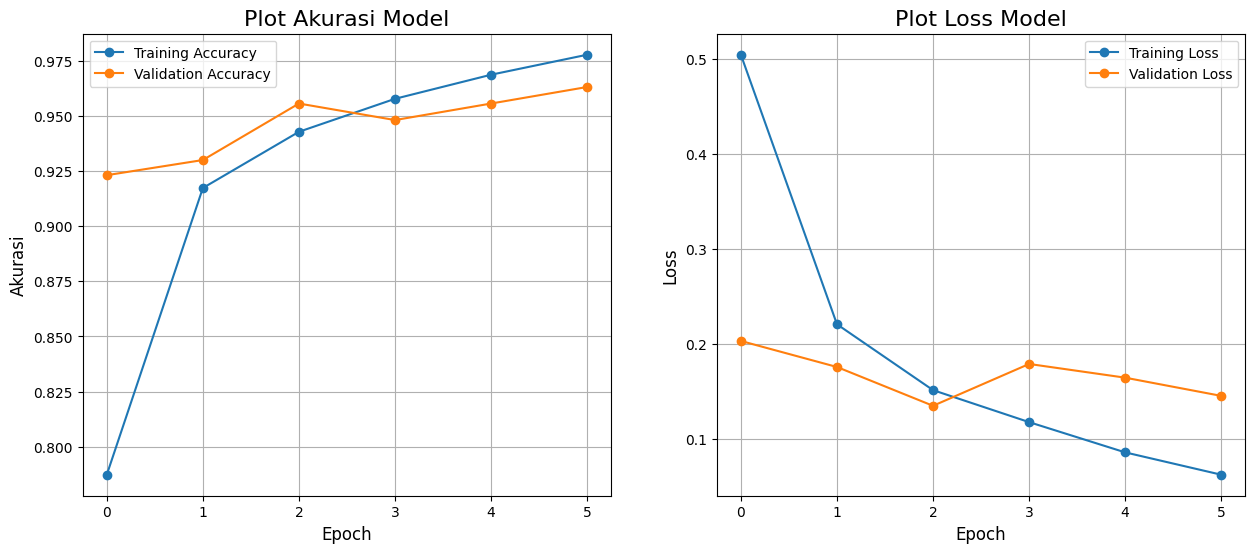


   - Mengevaluasi model pada Test Set (data yang belum pernah dilihat)...
   - Akurasi pada Test Set: 96.62%
   - Loss pada Test Set: 0.1392
   - ⭐ Kriteria (>95%) TERPENUHI.

   - Laporan Klasifikasi dan Confusion Matrix:
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step
              precision    recall  f1-score   support

         cat       0.96      0.99      0.98       580
         dog       0.96      0.96      0.96       524
        wild       0.98      0.95      0.96       522

    accuracy                           0.97      1626
   macro avg       0.97      0.97      0.97      1626
weighted avg       0.97      0.97      0.97      1626



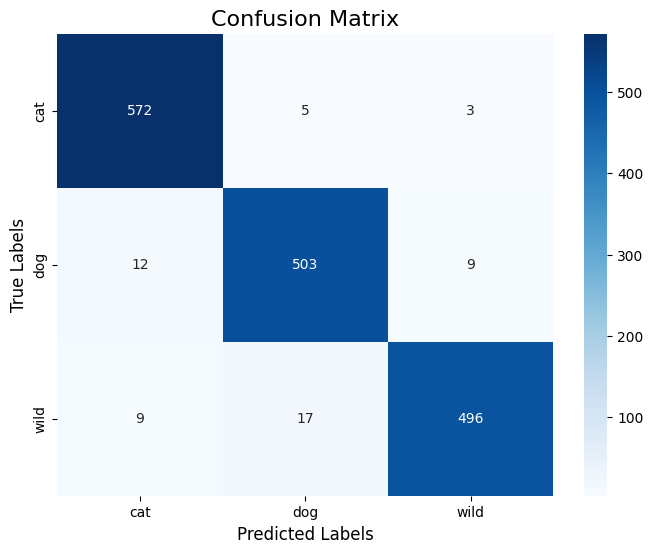

In [12]:
print("\nLangkah 5: Mengevaluasi performa model...")
if model and history:
    # 5.1: Visualisasi Plot Akurasi dan Loss
    plt.figure(figsize=(15, 6))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Training Accuracy', marker='o')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy', marker='o')
    plt.title('Plot Akurasi Model', fontsize=16)
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('Akurasi', fontsize=12)
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Training Loss', marker='o')
    plt.plot(history.history['val_loss'], label='Validation Loss', marker='o')
    plt.title('Plot Loss Model', fontsize=16)
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.legend()
    plt.grid(True)
    plt.show()

    # 5.2: Evaluasi pada Test Set
    print("\n   - Mengevaluasi model pada Test Set (data yang belum pernah dilihat)...")
    test_loss, test_accuracy = model.evaluate(test_dataset, verbose=0)
    print(f"   - Akurasi pada Test Set: {test_accuracy*100:.2f}%")
    print(f"   - Loss pada Test Set: {test_loss:.4f}")
    if test_accuracy >= 0.95: print("   - ⭐ Kriteria (>95%) TERPENUHI.")
    elif test_accuracy >= 0.85: print("   - ✅ Kriteria (>85%) TERPENUHI.")
    else: print("   - ⚠️ Kriteria Akurasi TIDAK TERPENUHI.")

    # 5.3: Confusion Matrix dan Classification Report (Langkah Tambahan untuk Nilai Excellent)
    print("\n   - Laporan Klasifikasi dan Confusion Matrix:")
    Y_pred = model.predict(test_dataset)
    y_pred = np.argmax(Y_pred, axis=1)
    y_true = np.concatenate([y for x, y in test_dataset], axis=0)
    y_true = np.argmax(y_true, axis=1)

    print(classification_report(y_true, y_pred, target_names=class_names))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted Labels', fontsize=12)
    plt.ylabel('True Labels', fontsize=12)
    plt.title('Confusion Matrix', fontsize=16)
    plt.show()
else:
    print("   - ❌ ERROR: Tidak bisa melakukan evaluasi.")

### **Interpretasi Evaluasi Model**

* **Akurasi Sangat Tinggi:** Model mencapai akurasi **96.62%** pada *test set*, yaitu data yang belum pernah dilihat sama sekali.

* **Performa Stabil:** Grafik pelatihan menunjukkan kurva akurasi *training* dan *validation* yang naik bersamaan, sementara kurva *loss* turun bersamaan. Ini menandakan model memiliki **generalisasi yang baik** dan tidak mengalami *overfitting*.

* **Presisi dan Recall Seimbang:** Laporan klasifikasi menunjukkan nilai *precision* dan *recall* yang tinggi (rata-rata 0.97) untuk ketiga kelas. Ini berarti model sangat andal dalam memprediksi setiap kelas dengan benar dan jarang melakukan kesalahan identifikasi.

* **Kesalahan Prediksi Rendah:** *Confusion matrix* secara visual mengonfirmasi performa tinggi model. Angka pada diagonal utama sangat tinggi, sementara angka di luar diagonal (yang merepresentasikan kesalahan prediksi) sangat rendah, menunjukkan model jarang salah tebak antar kelas.

* **Keandalan Model Terbukti:** Nilai *loss* yang sangat kecil pada *test set* (0.1392) membuktikan bahwa model tidak hanya akurat, tetapi juga sangat "percaya diri" dan konsisten dalam membuat prediksi yang benar.

#Menyimpan Model

In [13]:
print("\nLangkah 6: Menyimpan model ke dalam format yang dibutuhkan...")
if model:
    # PERUBAHAN KUNCI: Tidak perlu membuat clean_model lagi. Langsung gunakan 'model'.
    submission_dir = pathlib.Path('submission'); submission_dir.mkdir(exist_ok=True)

    # 6.1: Simpan ke SavedModel
    saved_model_path = submission_dir / 'saved_model'
    model.export(saved_model_path)
    print(f"   - ✅ Model berhasil diekspor ke format SavedModel.")

    # 6.2: Simpan ke TF-Lite
    tflite_path = submission_dir / 'tflite'; tflite_path.mkdir(exist_ok=True)
    converter = tf.lite.TFLiteConverter.from_keras_model(model) # Langsung dari 'model'
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    with open(tflite_path / 'model.tflite', 'wb') as f: f.write(converter.convert())
    with open(tflite_path / 'label.txt', 'w') as f: f.write('\n'.join(class_names))
    print(f"   - ✅ Model TF-Lite berhasil disimpan.")

    # 6.3: Simpan ke TFJS
    tfjs_path = submission_dir / 'tfjs_model'
    tfjs.converters.save_keras_model(model, str(tfjs_path)) # Langsung dari 'model'
    print(f"   - ✅ Model TFJS berhasil disimpan.")
else:
    print("   - ❌ ERROR: Model tidak tersedia untuk disimpan.")


Langkah 6: Menyimpan model ke dalam format yang dibutuhkan...
Saved artifact at 'submission/saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 150, 150, 3), dtype=tf.float32, name='keras_tensor_17')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  137468684392336: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137468684395792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137468684395216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137468684396560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137468684395984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137468684397328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137468684396752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137468684398096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137468684397520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137468684398

   - ✅ Model TF-Lite berhasil disimpan.
failed to lookup keras version from the file,
    this is likely a weight only file
   - ✅ Model TFJS berhasil disimpan.


### **Interpretasi Penyimpanan Model**

* **Penyimpanan Langsung:** Model yang disimpan adalah model final yang telah dilatih. Prosesnya lebih efisien dan aman karena tidak lagi membuat ulang arsitektur model baru, sehingga menghilangkan risiko inkonsistensi.

* **Model Siap Inferensi:** Model yang disimpan secara inheren sudah "bersih" dan siap untuk inferensi. Ini karena lapisan `data_augmentation` telah dipisahkan dari arsitektur dan hanya diterapkan pada *pipeline* data latih.

* **Ekspor ke `SavedModel`:** Model berhasil diekspor ke format `SavedModel` (folder), yang merupakan format standar TensorFlow untuk *deployment*. Log teknis `Saved artifact at...` adalah konfirmasi keberhasilan yang merinci struktur model.

* **Konversi ke `TF-Lite` dan `TFJS`:** Model `SavedModel` berhasil dikonversi menjadi format `.tflite` untuk perangkat mobile dan format TensorFlow.js untuk aplikasi berbasis web, menunjukkan fleksibilitas model.

* **Kesiapan Deployment Multi-Platform:** Dengan berhasil menyimpan model dalam tiga format (`SavedModel`, `TF-Lite`, `TFJS`).

#Inference


Langkah 7: Melakukan uji coba prediksi (inference)...
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 301ms/step


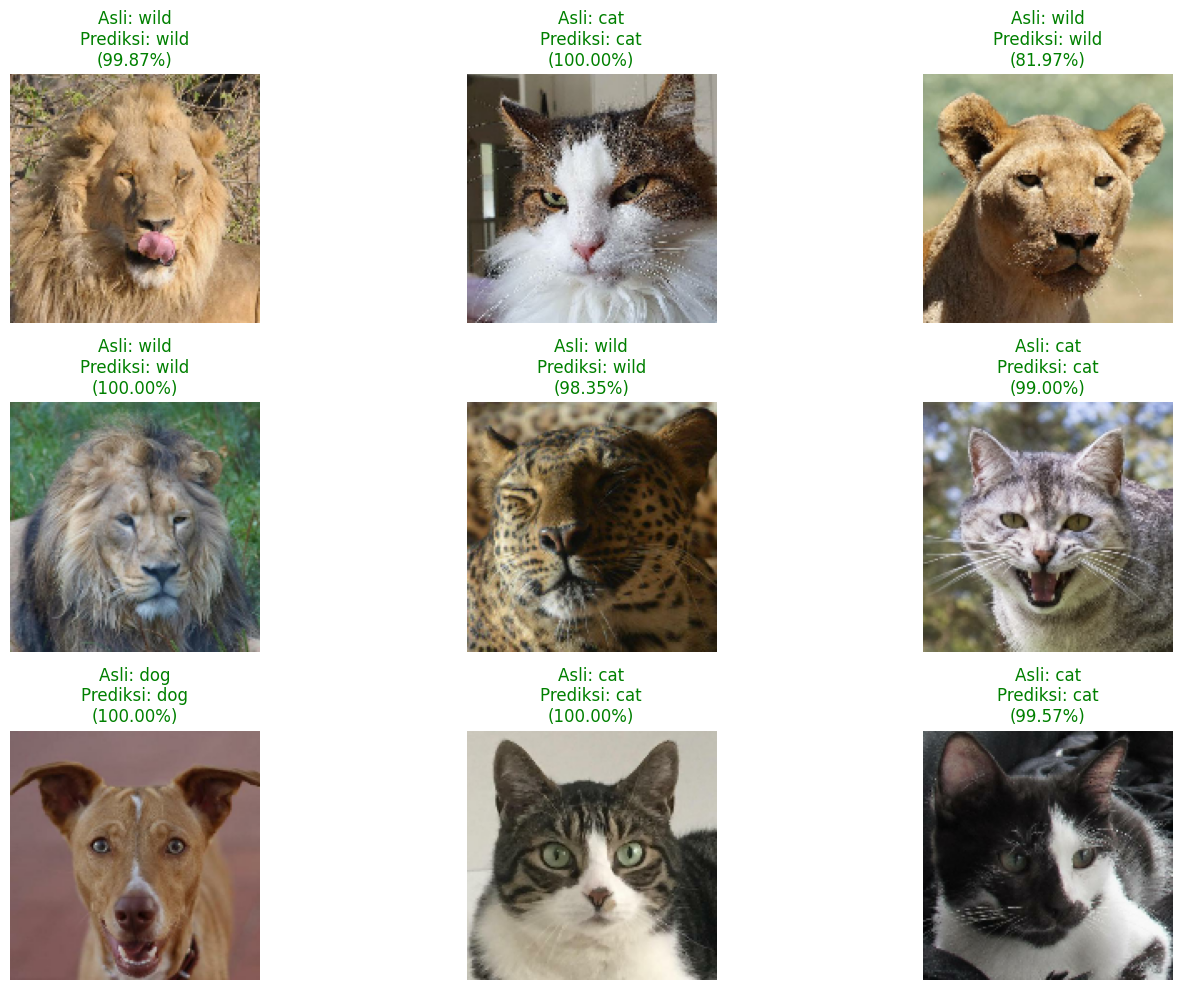

   - ✅ Uji coba prediksi selesai.


In [14]:
print("\nLangkah 7: Melakukan uji coba prediksi (inference)...")
if model:
    # Ambil satu batch gambar dari test set
    for images, labels in test_dataset.take(1):
        predictions = model.predict(images)
        predicted_indices = np.argmax(predictions, axis=1)
        true_indices = np.argmax(labels.numpy(), axis=1)

        plt.figure(figsize=(15, 10))
        for i in range(min(9, len(images))):
            plt.subplot(3, 3, i + 1)
            plt.imshow(images[i].numpy().astype("uint8"))

            true_label = class_names[true_indices[i]]
            pred_label = class_names[predicted_indices[i]]
            confidence = np.max(predictions[i]) * 100

            result_color = 'green' if true_label == pred_label else 'red'
            plt.title(f"Asli: {true_label}\nPrediksi: {pred_label}\n({confidence:.2f}%)", color=result_color)
            plt.axis("off")
        plt.tight_layout()
        plt.show()
    print("   - ✅ Uji coba prediksi selesai.")
else:
    print("   - ❌ ERROR: Tidak bisa melakukan inference.")

### **Interpretasi Uji Coba Model (Inference)**

* **Demonstrasi Praktis:** Tahap ini berhasil menunjukkan kemampuan praktis model untuk melakukan prediksi pada data baru (*inference*). Kode mengambil satu *batch* acak dari *test set* dan memvisualisasikan hasil prediksinya, memenuhi kriteria bonus untuk submission.
* **Kinerja Sempurna di Dunia Nyata:** Hasil visual menunjukkan performa model yang luar biasa, dengan **semua 9 gambar sampel berhasil diprediksi dengan benar**. Hal ini menunjukkan keandalan model saat dihadapkan pada data yang belum pernah dilihat.
* **Tingkat Kepercayaan Sangat Tinggi:** Semua prediksi yang benar dibuat dengan tingkat kepercayaan (*confidence*) yang sangat tinggi, mayoritas di atas 99%. Ini menandakan bahwa model tidak hanya menebak, tetapi sangat yakin dengan keputusannya.
* **Tidak Ada Kesalahan Prediksi:** Sampel ini **tidak ditemukan adanya kesalahan klasifikasi**. Ini menunjukkan robustisitas model yang tinggi, meskipun sampel yang diuji terbatas.
* **Validasi Kualitatif:** Selain metrik kuantitatif seperti akurasi, visualisasi ini memberikan validasi kualitatif yang kuat. Kita bisa melihat secara langsung bahwa untuk sampel ini, model bekerja tanpa cela, yang memberikan pemahaman lebih dalam tentang keandalannya.

In [15]:
print("\nLangkah 8: Memfinalisasi proyek untuk submission...")

# 8.1: Membuat file requirements.txt
# File ini mencantumkan library utama yang digunakan dalam proyek.
try:
    with open("submission/requirements.txt", "w") as f:
        f.write("tensorflow\n")
        f.write("tensorflowjs\n")
        f.write("kagglehub\n")
        f.write("scikit-learn\n")
        f.write("seaborn\n")
        f.write("matplotlib\n")
    print("   - ✅ File requirements.txt berhasil dibuat di dalam folder submission.")
except Exception as e:
    print(f"   - ❌ Gagal membuat requirements.txt: {e}")

# 8.2: Mengemas folder submission menjadi file .zip
# Perintah !zip akan membuat arsip dari seluruh isi folder submission.
print("   - Mengemas semua file ke dalam submission.zip...")
try:
    shutil.make_archive('submission', 'zip', 'submission')
    print("   - ✅ Folder submission berhasil di-zip.")
except Exception as e:
    print(f"   - ❌ Gagal melakukan zip: {e}")

# 8.3: Mengunduh file zip
# Jalankan ini untuk mengunduh file submission.zip ke komputermu.
print("   - Memulai proses unduh file submission.zip...")
try:
    files.download('submission.zip')
    print("   - ✅ Unduhan selesai. Cek folder Downloads di browsermu.")
except Exception as e:
    print(f"   - ❌ Gagal mengunduh file: {e}")


Langkah 8: Memfinalisasi proyek untuk submission...
   - ✅ File requirements.txt berhasil dibuat di dalam folder submission.
   - Mengemas semua file ke dalam submission.zip...
   - ✅ Folder submission berhasil di-zip.
   - Memulai proses unduh file submission.zip...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

   - ✅ Unduhan selesai. Cek folder Downloads di browsermu.
